# CLASS vs CosmoPower posteriors

Loads the same run from both pipelines and plots the posteriors on top of each other. Run from the `omega_m/` root.

In [5]:
from pathlib import Path
import glob, re, ast
import matplotlib.pyplot as plt
from getdist import loadMCSamples, plots

RUN = "model_lcdm__param_one_bin"          # folder name, same in both pipelines
RUN_cross = "model_lcdm_from_class__param_one_bin"          # folder name, same in both pipelines
CHAINS = {
    "CLASS":      Path("with_class/chains") / RUN,
    "CosmoPower": Path("with_cosmopower/chains") / RUN_cross,
}
BURN_IN = 0.3
SAVE = True                                 # save figures to posteriors_<RUN>.pdf/png

In [6]:
LABELS = {"omega_b": r"\omega_b", "h": "h", "tau_reio": r"\tau_\mathrm{reio}", "n_s": "n_s",
          "ln10^{10}A_s": r"\ln(10^{10}A_s)", "H0": "H_0"}

def load(chain_dir, label):
    # MontePython folder -> GetDist samples (omega_b rescaled to physical, prior ranges from log.param)
    roots = [str(f)[:-len(".paramnames")] for f in Path(chain_dir).glob("*.paramnames")]
    roots = [r for r in roots if any(Path(c).stat().st_size > 0 for c in glob.glob(glob.escape(r) + "_[0-9]*.txt"))]
    root = max(roots, key=lambda r: len(glob.glob(glob.escape(r) + "_[0-9]*.txt")))   # most chain files
    s = loadMCSamples(root, settings={"ignore_rows": BURN_IN}, no_cache=True)

    logp = {}
    for name, row in re.findall(r"^data\.parameters\[['\"](.+?)['\"]\]\s*=\s*(\[.*?\])",
                                (Path(chain_dir) / "log.param").read_text(), re.M):
        logp[name] = ast.literal_eval(row)          # [mean, min, max, sigma, scale, role]
    ranges = {}
    for i, n in enumerate(s.getParamNames().list()):
        if n in logp:
            _, lo, hi, _, scale, role = logp[n]
            s.samples[:, i] *= scale
            if role != "derived":
                ranges[n] = (None if lo in (None, -1) else lo * scale, None if hi in (None, -1) else hi * scale)
    s.setRanges(ranges)
    for p in s.paramNames.names:
        p.label = LABELS.get(p.name, p.label)
        m = re.fullmatch(r"omega_m(\d+)", p.name)
        if m:
            p.label = rf"\omega_{{m,{m.group(1)}}}"
    s.updateBaseStatistics()
    print(f"{label:<11} {root}")
    return s

samples = {lab: load(d, lab) for lab, d in CHAINS.items()}
params = [n for n in samples["CLASS"].getParamNames().list()
          if n != "H0" and all(n in s.getParamNames().list() for s in samples.values())]

with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__1.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__2.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__3.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__4.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__5.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__6.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__7.txt
with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000__8.txt
Removed 0.3 as burn in
CLASS       with_class/chains/model_lcdm__param_one_bin/2026-10-09_100000_
with_cosmopower/chains/model_lcdm_from_class__param_one_bin/2026-10-14_100000__1.txt
with_cosmopower/chains/model_lcdm_from_class__param_one_bin/2026-10-14_100000__2.txt
with_cosmopower/chains/model_lcdm_from_class__param_one_bin/2026-10-14_100000__3.txt
with_cosmopower/chains/model_lcdm_from_class__param_one_bin/2026-10-14_100000__4.txt
with_cosmo

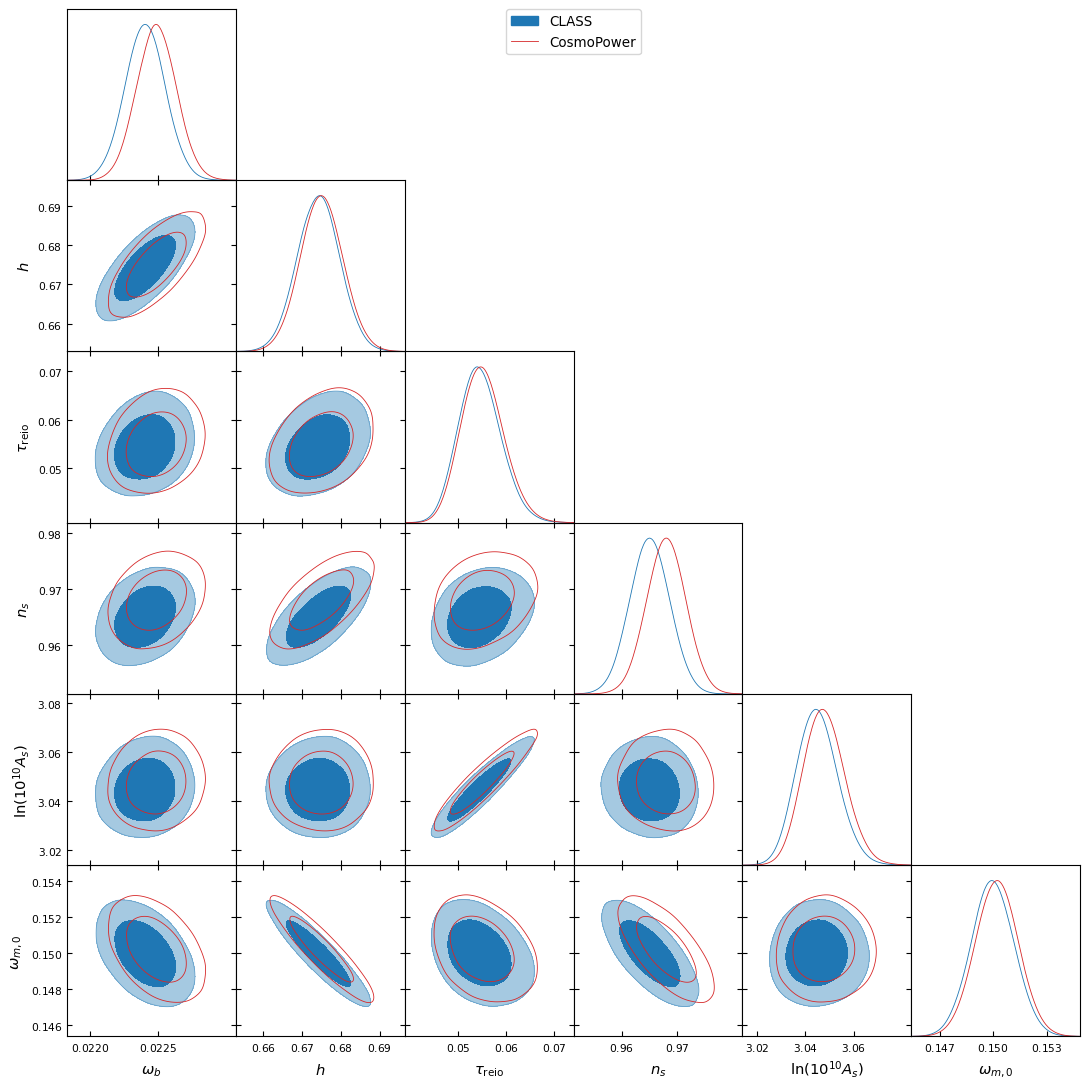

In [7]:
g = plots.get_subplot_plotter(width_inch=11)
g.settings.legend_fontsize = 13
g.triangle_plot(list(samples.values()), params, filled=[True, False],
                contour_colors=["C0", "C3"], legend_labels=list(samples))
if SAVE:
    g.export(f"posteriors_{RUN}.pdf"); g.export(f"posteriors_{RUN}.png")
plt.show()

In [8]:
# 68% constraints side by side
for n in params:
    print("   ".join(f"{lab}: {s.getInlineLatex(n, limit=1):<40}" for lab, s in samples.items()))

CLASS: \omega_b = 0.02240\pm 0.00015              CosmoPower: \omega_b = 0.02249\pm 0.00015           
CLASS: h = 0.6742\pm 0.0055                       CosmoPower: h = 0.6750\pm 0.0055                    
CLASS: \tau_\mathrm{reio} = 0.0545^{+0.0040}_{-0.0047}   CosmoPower: \tau_\mathrm{reio} = 0.0551^{+0.0040}_{-0.0048}
CLASS: n_s = 0.9651\pm 0.0036                     CosmoPower: n_s = 0.9681\pm 0.0035                  
CLASS: \ln(10^{10}A_s) = 3.0450^{+0.0078}_{-0.0090}   CosmoPower: \ln(10^{10}A_s) = 3.0479^{+0.0079}_{-0.0090}
CLASS: \omega_{m,0} = 0.1500\pm 0.0012            CosmoPower: \omega_{m,0} = 0.1502\pm 0.0012         
